# 01 · Data acquisition & EDA
Downloads the original UCI Cleveland file, validates it, and produces descriptive figures. EDA never drives model selection.

In [1]:
import os, pathlib
if pathlib.Path.cwd().name == 'notebooks':
    os.chdir('..')
import warnings; warnings.filterwarnings('ignore')
from IPython.display import Image, display

In [2]:
from heartops.data import acquire, FEATURES
from heartops.eda import make_figures, summary_table
data = acquire()
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Shape, types and missing values
`ca` and `thal` carry `?` markers in the raw file. They stay as NaN in the cleaned CSV and are imputed *inside* CV folds.

In [3]:
print(data.shape)
summary_table(data)

(303, 14)


,missing,unique,min,median,max
age,0,41,29.0,56.0,77.0
sex,0,2,0.0,1.0,1.0
cp,0,4,1.0,3.0,4.0
trestbps,0,50,94.0,130.0,200.0
chol,0,152,126.0,241.0,564.0
fbs,0,2,0.0,0.0,1.0
restecg,0,3,0.0,1.0,2.0
thalach,0,91,71.0,153.0,202.0
exang,0,2,0.0,0.0,1.0
oldpeak,0,40,0.0,0.8,6.2


In [4]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## Class balance

In [5]:
data.target.value_counts(normalize=True).rename({0: 'absent', 1: 'present'})

target
absent     0.541254
present    0.458746
Name: proportion, dtype: float64

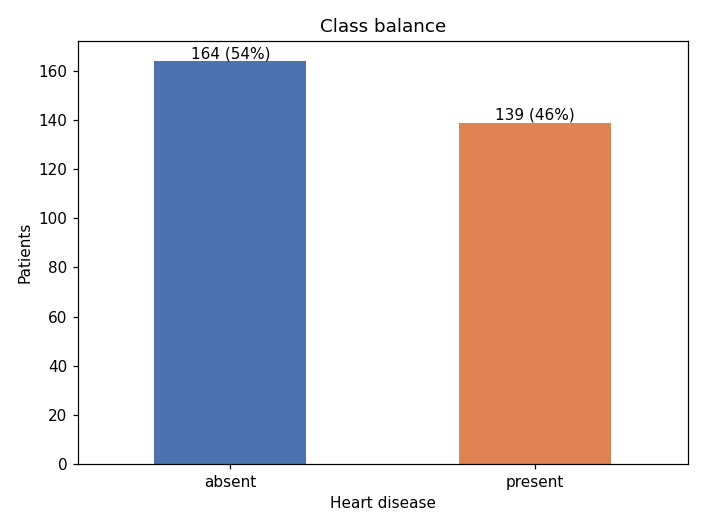

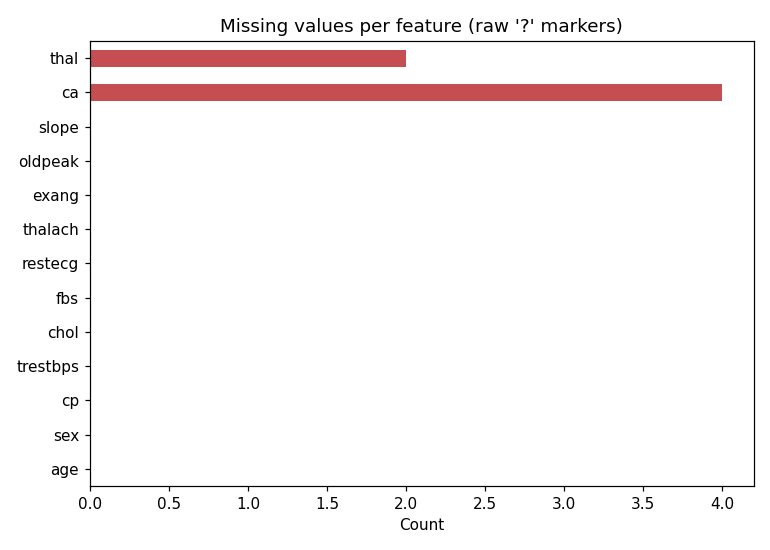

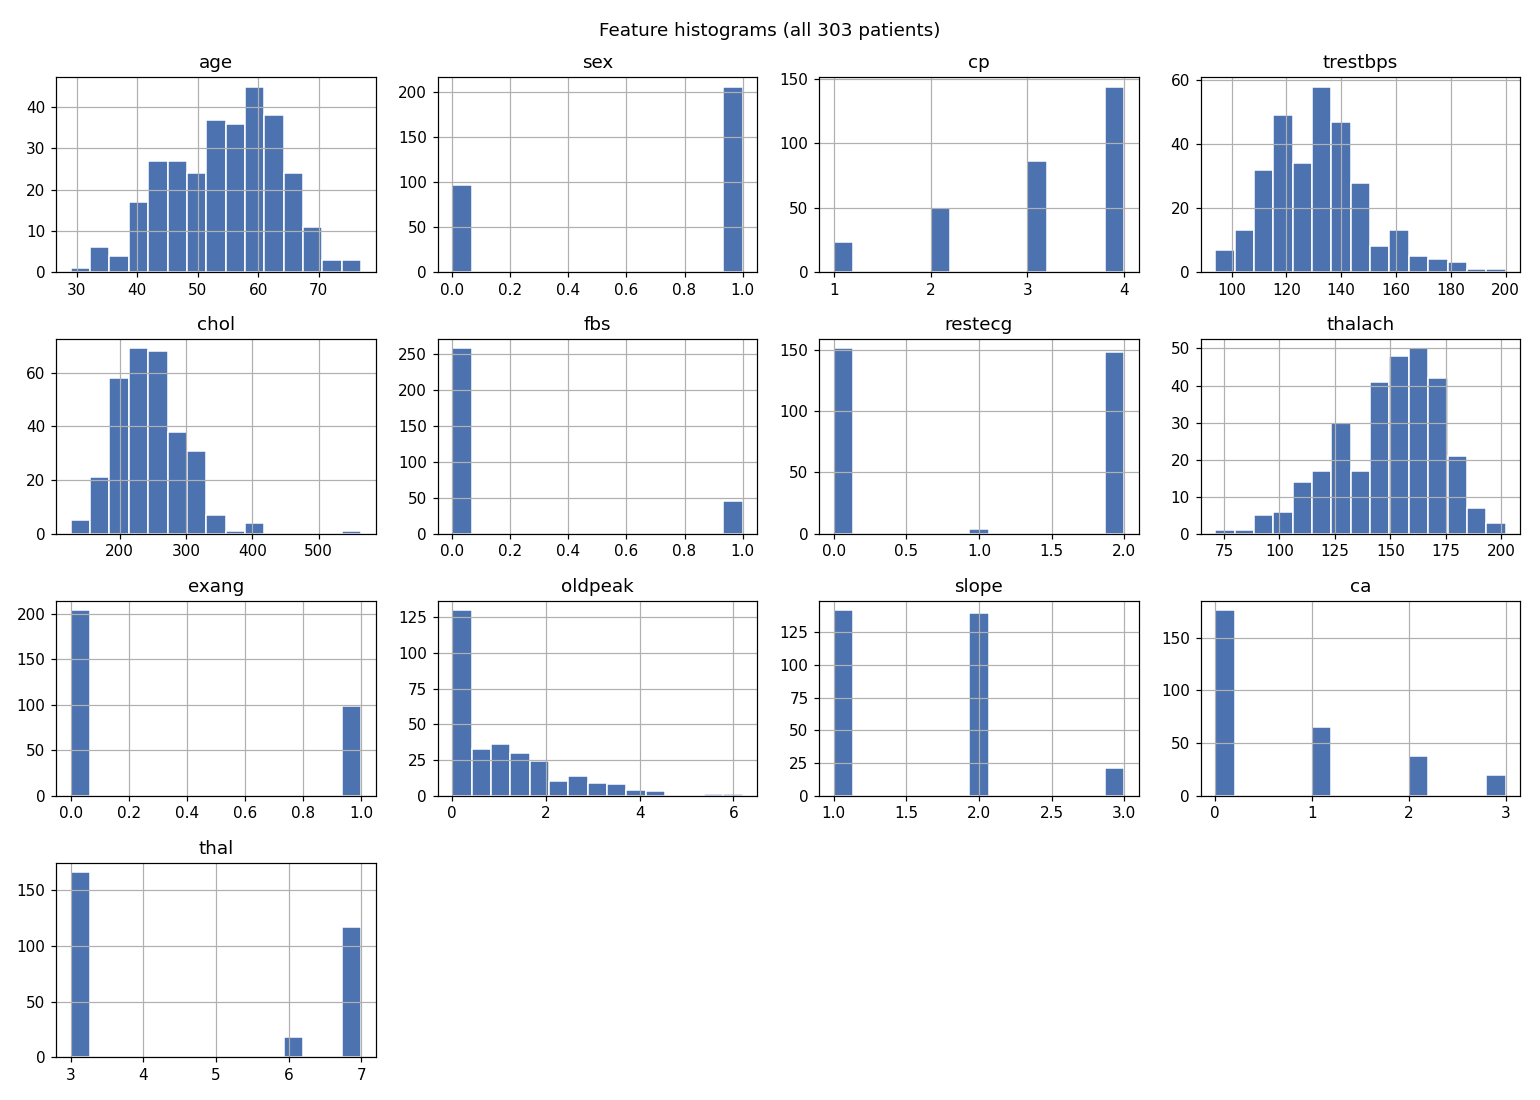

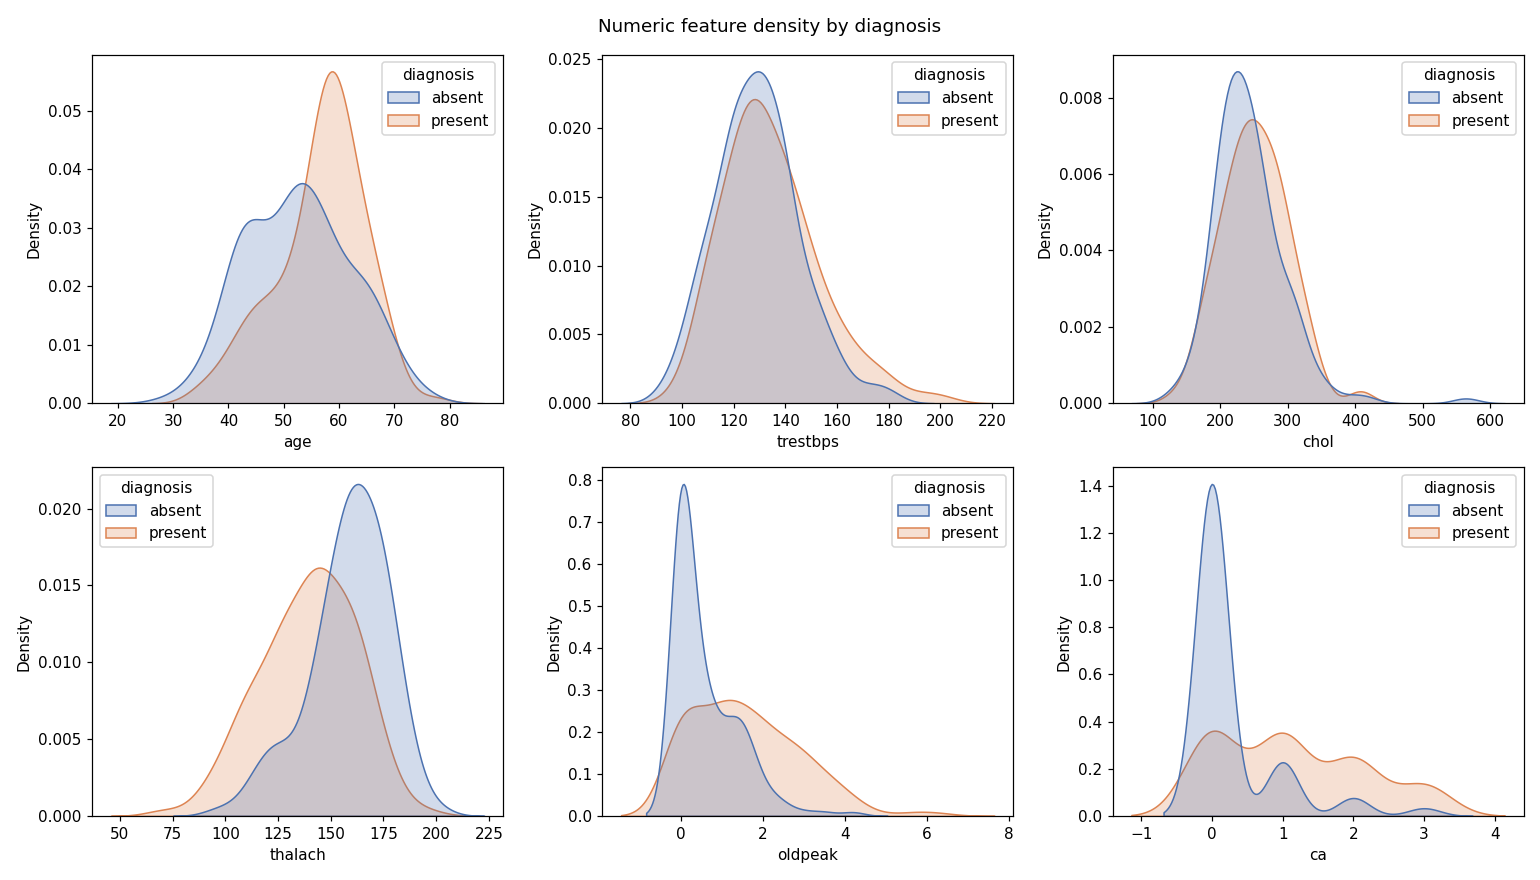

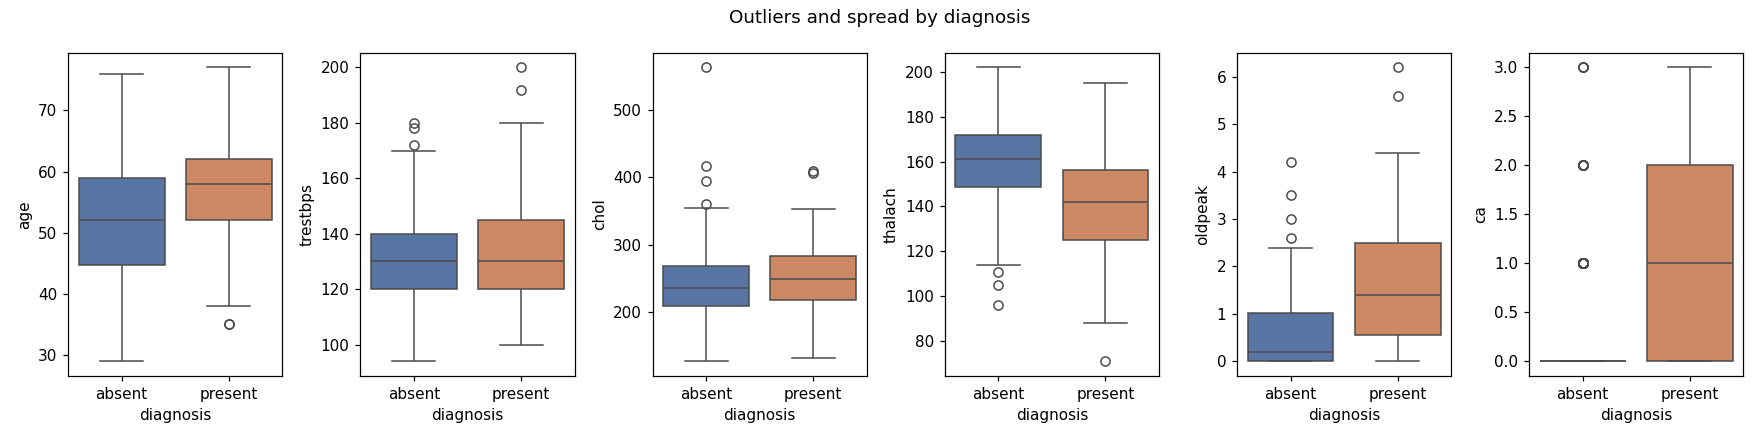

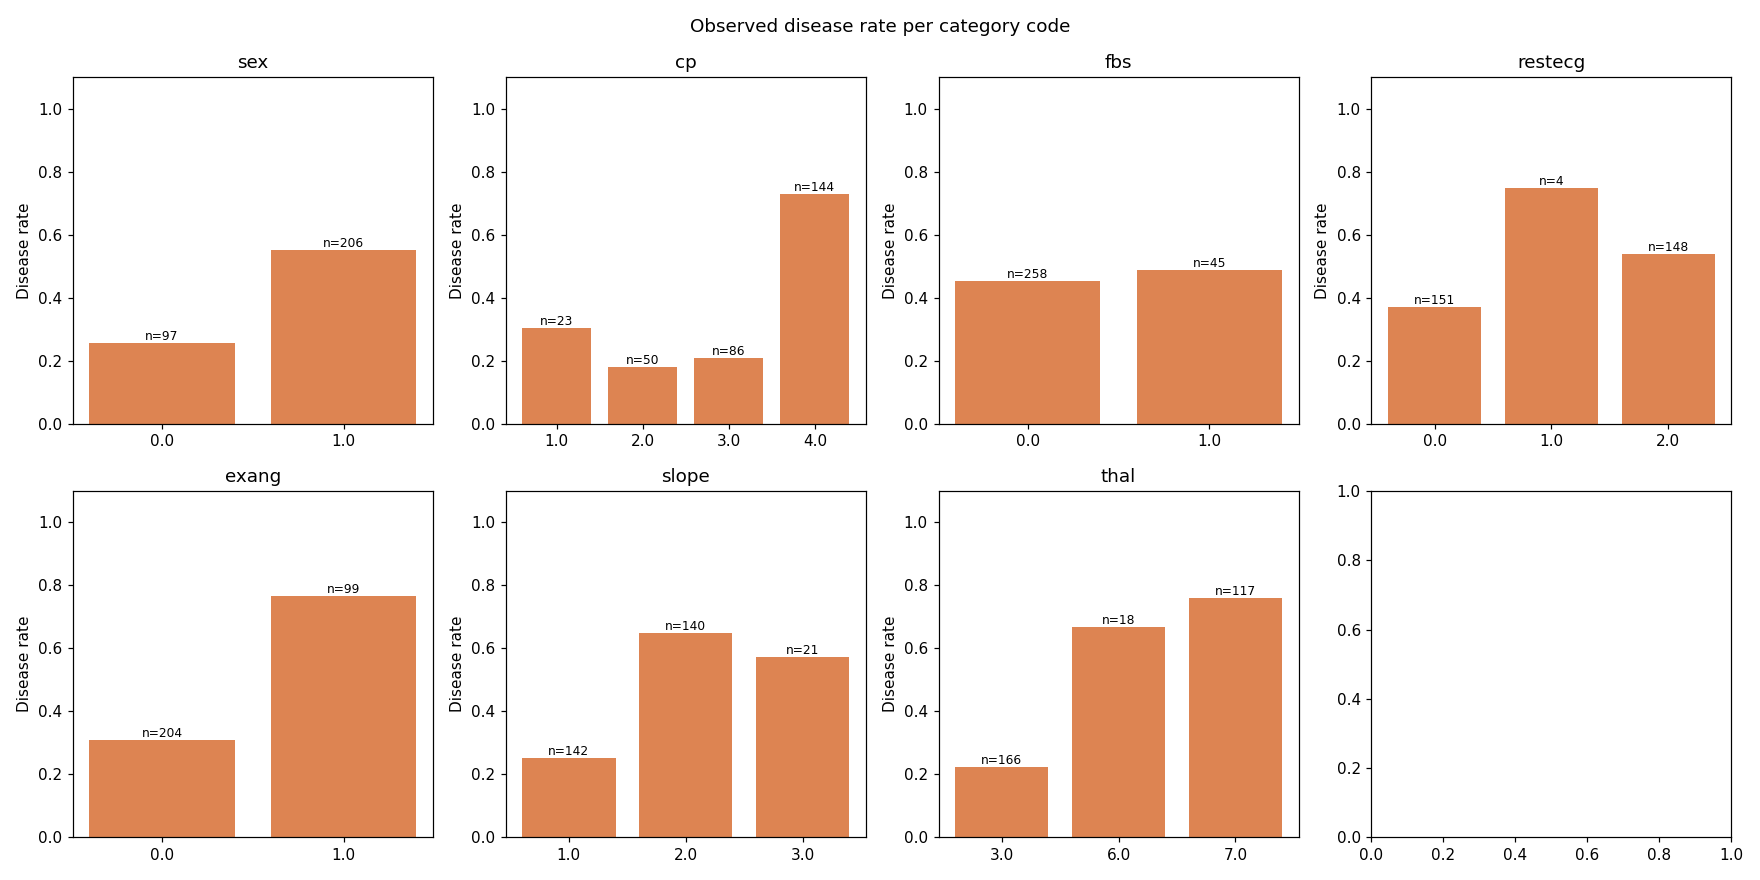

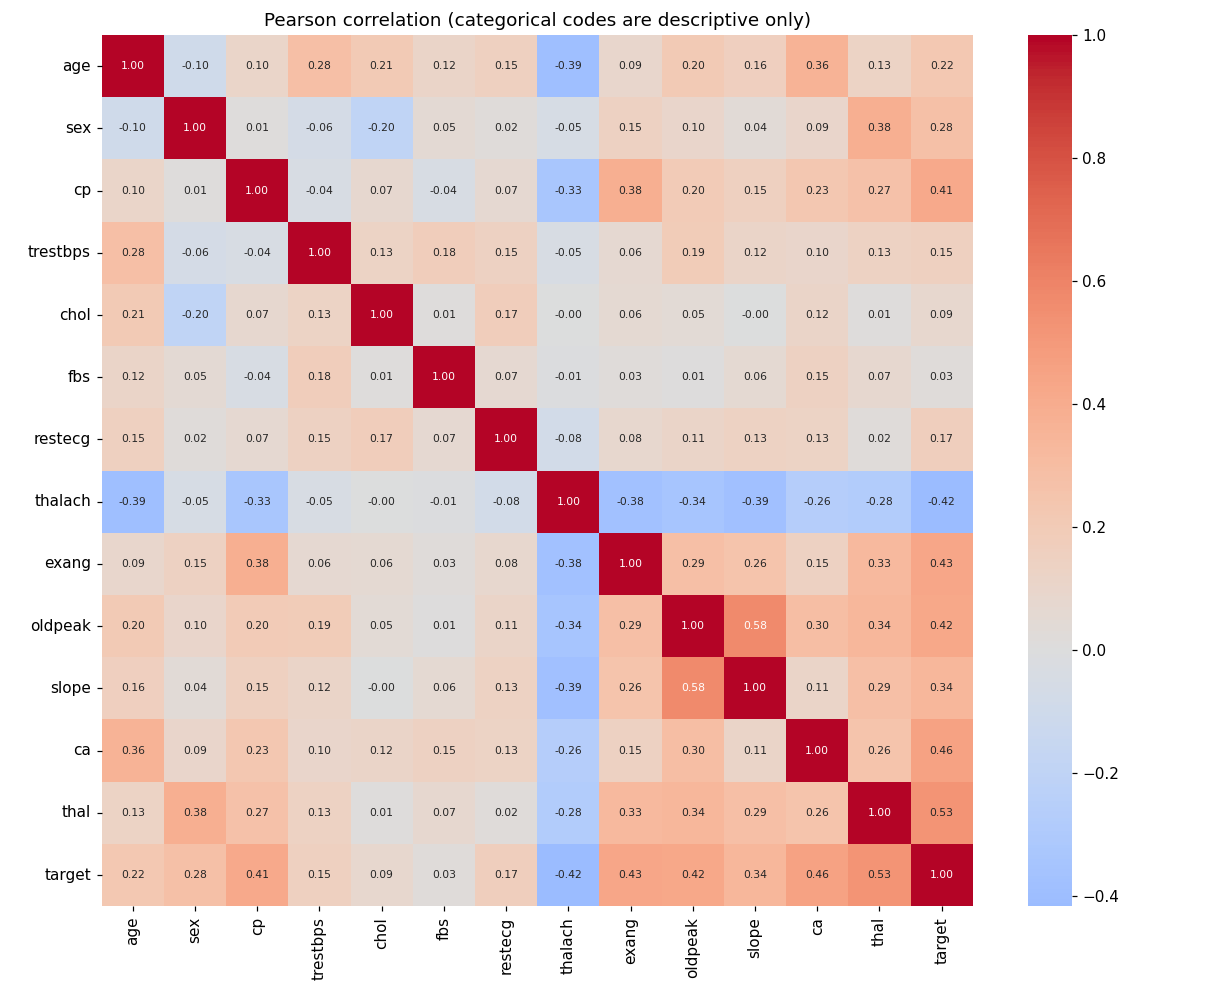

In [6]:
names = make_figures(data)
for name in ['class_balance', 'missing_values', 'histograms', 'numeric_by_target', 'boxplots', 'categorical_rates', 'correlations']:
    display(Image(f'reports/figures/{name}.png'))

## Observations
- Classes are roughly balanced (54% / 46%), so accuracy is meaningful but ROC-AUC is used for selection.
- `thalach` is lower and `oldpeak` higher for diseased patients; `cp=4` (asymptomatic) and `thal=7` show high disease rates.
- `chol` and `trestbps` separate the classes weakly.
- Only 6 missing values in total (ca=4, thal=2) → simple median/mode imputation is sufficient.

In [7]:
data.corr()['target'].drop('target').sort_values(key=abs, ascending=False).round(3)

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64